# Steam 游戏数据分析 · 第一阶段：数据清洗与探索性分析

**研究问题：** 哪些因素和 Steam 游戏的口碑（好评率）有关？

**数据来源：** [FronkonGames Steam Games Dataset](https://huggingface.co/datasets/FronkonGames/steam-games-dataset)（MIT 协议），约 12.4 万款 Steam 游戏，数据截至 2026 年 9 月。

**第一阶段内容：**
1. 读取数据，了解每一列的含义
2. 数据清洗：去重、日期转换、拆分"预估拥有人数"、计算好评率
3. 四张探索性图表：发行趋势、类型分布、好评率分布、价格与好评率


## 1. 导入库并读取数据

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# 图表统一风格
plt.rcParams.update({
    "figure.figsize": (9, 5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
})
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)
BLUE = "#1F5FA8"

# parquet 是一种压缩的列式存储格式，比 CSV 小、读得快
df = pd.read_parquet("data/games.parquet")
print("行数, 列数:", df.shape)

行数, 列数: (124146, 41)


In [2]:
# 看看有哪些列、每列是什么类型
df.dtypes

appID                           str
name                            str
release_date                    str
estimated_owners                str
peak_ccu                      int64
required_age                  int64
price                       float64
dlc_count                     int64
detailed_description            str
short_description               str
supported_languages          object
full_audio_languages         object
reviews                         str
header_image                    str
website                         str
support_url                     str
support_email                   str
windows                        bool
mac                            bool
linux                          bool
metacritic_score              int64
metacritic_url                  str
user_score                    int64
positive                      int64
negative                      int64
score_rank                      str
achievements                  int64
recommendations             

In [3]:
# 看几个关键列的样子
df[["name", "release_date", "estimated_owners", "price", "positive", "negative", "genres"]].head()

,name,release_date,estimated_owners,price,positive,negative,genres
0,Black Dragon Mage Playtest,"Aug 1, 2023",0 - 0,0.00,0,0,[]
1,Supipara - Chapter 1 Spring Has Come!,"Jul 29, 2016",0 - 20000,5.24,252,3,[Adventure]
2,Mystery Solitaire The Black Raven,"May 6, 2019",0 - 20000,4.99,21,3,[Casual]
3,버튜버 파라노이아 - Vtuber Paranoia,"Oct 31, 2024",0 - 20000,8.99,0,0,"[Casual, Indie, Simulation]"
4,Maze Quest VR,"Apr 24, 2025",0 - 20000,4.99,0,0,"[Action, Early Access]"


**观察：**
- `release_date` 是文字（如 "Aug 1, 2023"），需要转成日期才能按年份统计。
- `estimated_owners` 是区间文字（如 "0 - 20000"），需要拆成数字。
- `positive` / `negative` 是好评数和差评数，可以算出好评率。
- `genres` 每一格是一个列表，一款游戏可以属于多个类型。

## 2. 数据清洗

In [4]:
n_raw = len(df)

# (1) 去掉没有名字的游戏，按 appID 去重
df = df[df["name"].str.strip() != ""]
df = df.drop_duplicates(subset="appID")

# (2) 发行日期：文字 -> 日期，再取出年份
df["release_date"] = pd.to_datetime(df["release_date"], format="mixed", errors="coerce")
df["year"] = df["release_date"].dt.year

# (3) 预估拥有人数："20000 - 50000" -> 两个数字列
owners = df["estimated_owners"].str.split(" - ", expand=True).astype("int64")
df["owners_low"] = owners[0]
df["owners_high"] = owners[1]

# (4) 评价总数与好评率（没有评价的游戏好评率记为缺失，而不是 0）
df["total_reviews"] = df["positive"] + df["negative"]
df["positive_rate"] = np.where(df["total_reviews"] > 0,
                               df["positive"] / df["total_reviews"], np.nan)

# (5) 是否免费
df["is_free"] = df["price"] == 0

print(f"清洗前 {n_raw:,} 行，清洗后 {len(df):,} 行")
print(f"日期无法解析的行数：{df['year'].isna().sum()}")
print(f"没有任何评价的游戏占比：{(df['total_reviews'] == 0).mean():.1%}")
print(f"免费游戏占比：{df['is_free'].mean():.1%}")
print(f"付费游戏价格中位数：${df.loc[~df['is_free'], 'price'].median():.2f}")

清洗前 124,146 行，清洗后 124,145 行
日期无法解析的行数：0
没有任何评价的游戏占比：33.2%
免费游戏占比：21.3%
付费游戏价格中位数：$3.59


**一个重要的清洗决定：** 很多游戏只有一两条评价，这时好评率要么是 0%、要么是 100%，没有参考价值。
所以分析好评率时，只保留**评价数 ≥ 10** 的游戏。

In [5]:
MIN_REVIEWS = 10
rated = df[df["total_reviews"] >= MIN_REVIEWS].copy()
print(f"评价数 ≥ {MIN_REVIEWS} 的游戏：{len(rated):,} 款，占全部的 {len(rated) / len(df):.1%}")

评价数 ≥ 10 的游戏：56,657 款，占全部的 45.6%


## 3. 图 1：Steam 每年新发行游戏数量

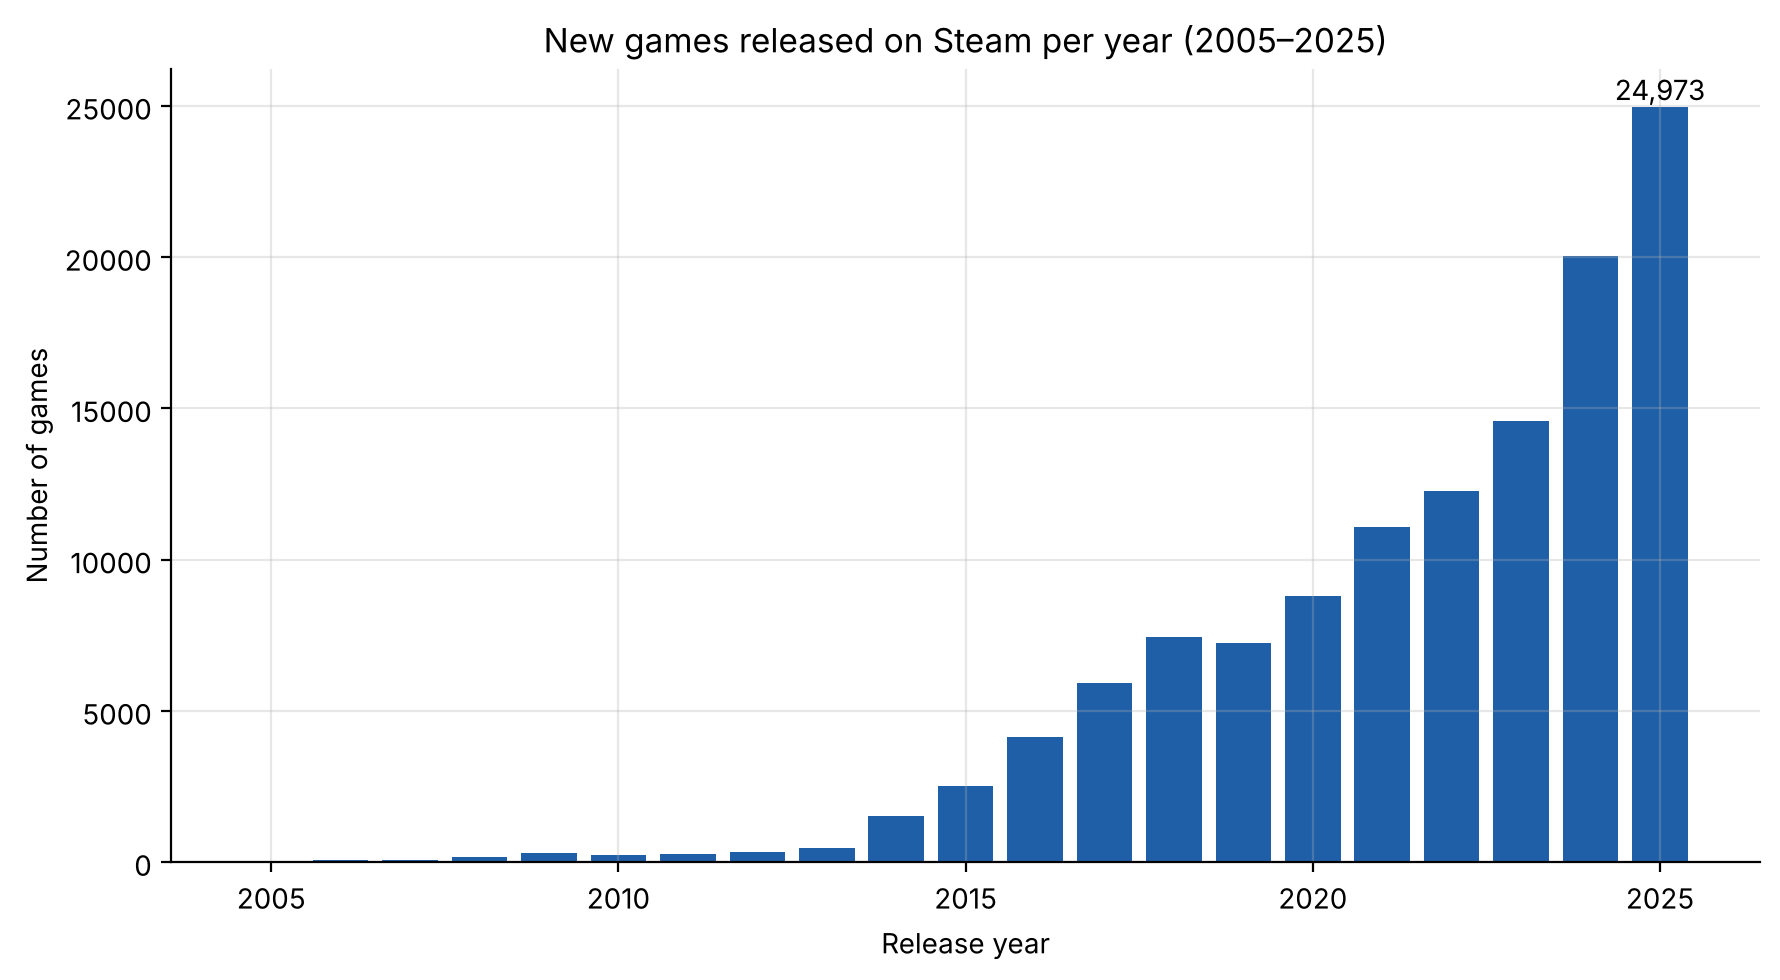

2015 年：2,515 款；2025 年：24,973 款，约为 2015 年的 10 倍
2020–2025 年发行的游戏占全部的 74%


In [6]:
# 2026 年数据只到 9 月，不完整，所以只画到 2025 年
per_year = df[df["year"].between(2005, 2025)].groupby("year").size()

fig, ax = plt.subplots()
ax.bar(per_year.index, per_year.values, color=BLUE)
ax.set_title("New games released on Steam per year (2005–2025)")
ax.set_xlabel("Release year")
ax.set_ylabel("Number of games")
ax.annotate(f"{per_year[2025]:,}", (2025, per_year[2025]), ha="center", va="bottom")
fig.tight_layout()
fig.savefig(FIG_DIR / "01_releases_per_year.png", dpi=150)
plt.show()

print(f"2015 年：{per_year[2015]:,} 款；2025 年：{per_year[2025]:,} 款，约为 2015 年的 {per_year[2025] / per_year[2015]:.0f} 倍")
print(f"2020–2025 年发行的游戏占全部的 {df['year'].between(2020, 2025).mean():.0%}")

## 4. 图 2：最常见的 10 种游戏类型

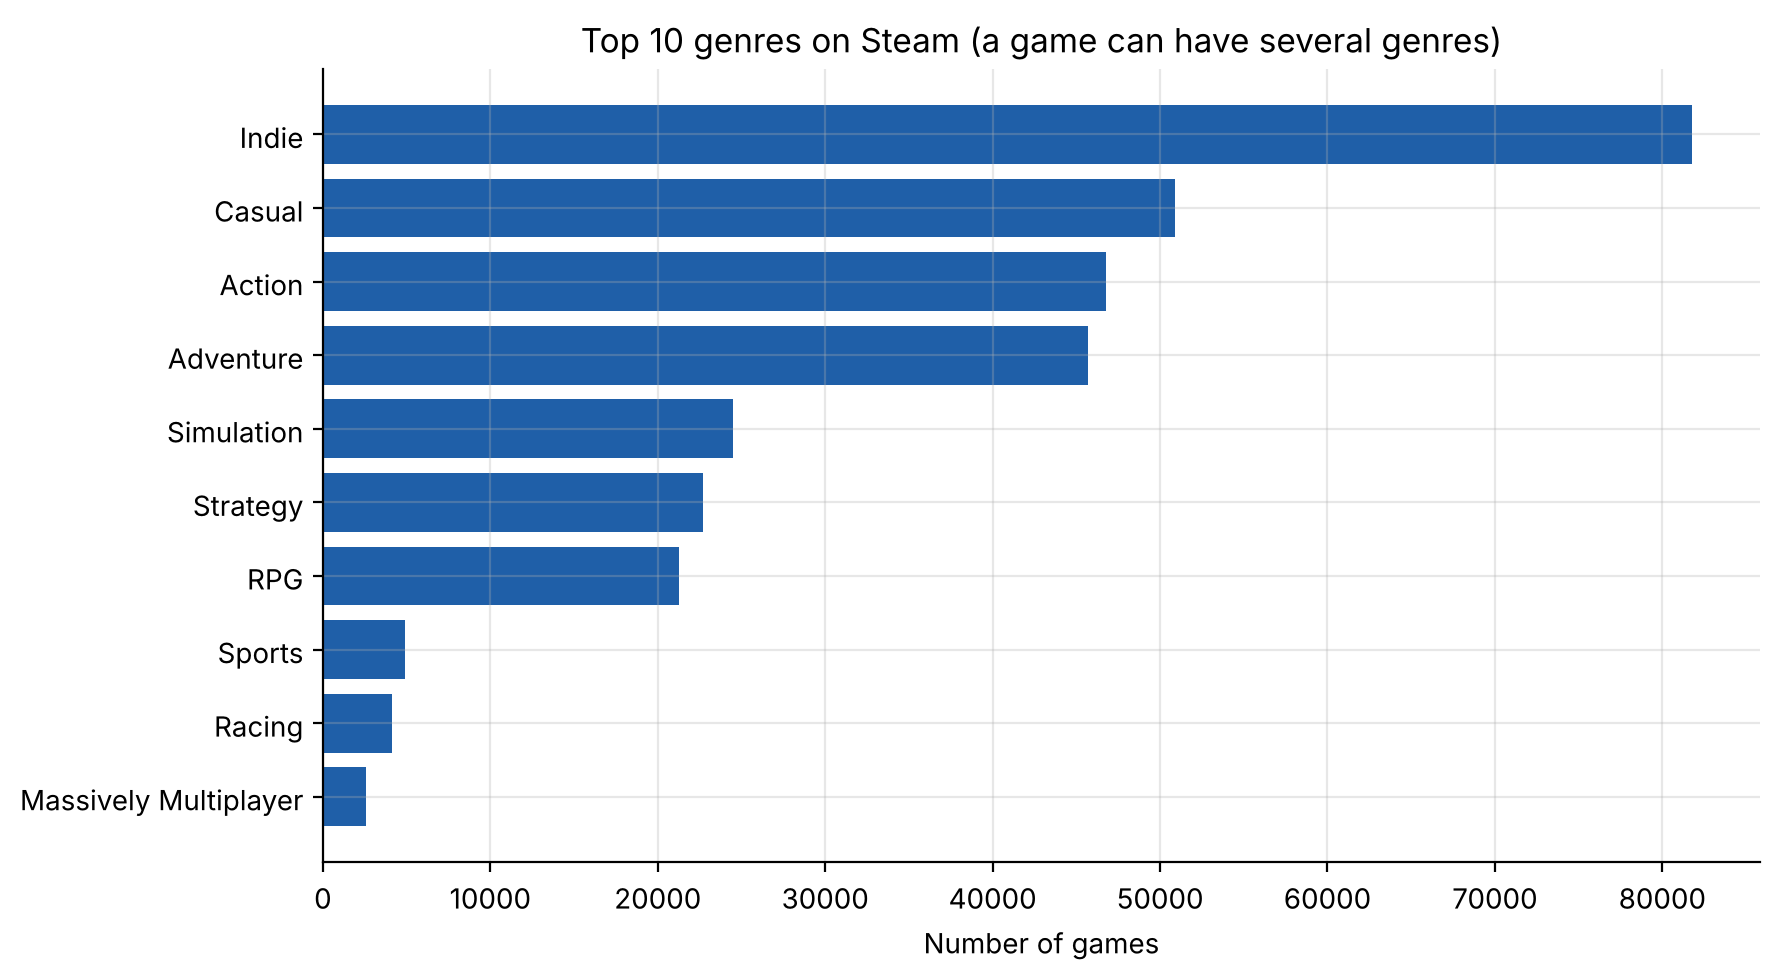

标记为 Indie（独立游戏）的占全部游戏的 66%


In [7]:
# explode：把列表"炸开"，一款游戏有几个类型就变成几行
genre_counts = df.explode("genres")["genres"].value_counts()

# "Free To Play" 和 "Early Access" 是销售方式，不是玩法类型，所以去掉
genre_counts = genre_counts.drop(["Free To Play", "Early Access"], errors="ignore").head(10)

fig, ax = plt.subplots()
ax.barh(genre_counts.index[::-1], genre_counts.values[::-1], color=BLUE)
ax.set_title("Top 10 genres on Steam (a game can have several genres)")
ax.set_xlabel("Number of games")
fig.tight_layout()
fig.savefig(FIG_DIR / "02_top_genres.png", dpi=150)
plt.show()

print(f"标记为 Indie（独立游戏）的占全部游戏的 {genre_counts['Indie'] / len(df):.0%}")

## 5. 图 3：好评率分布（评价数 ≥ 10 的游戏）

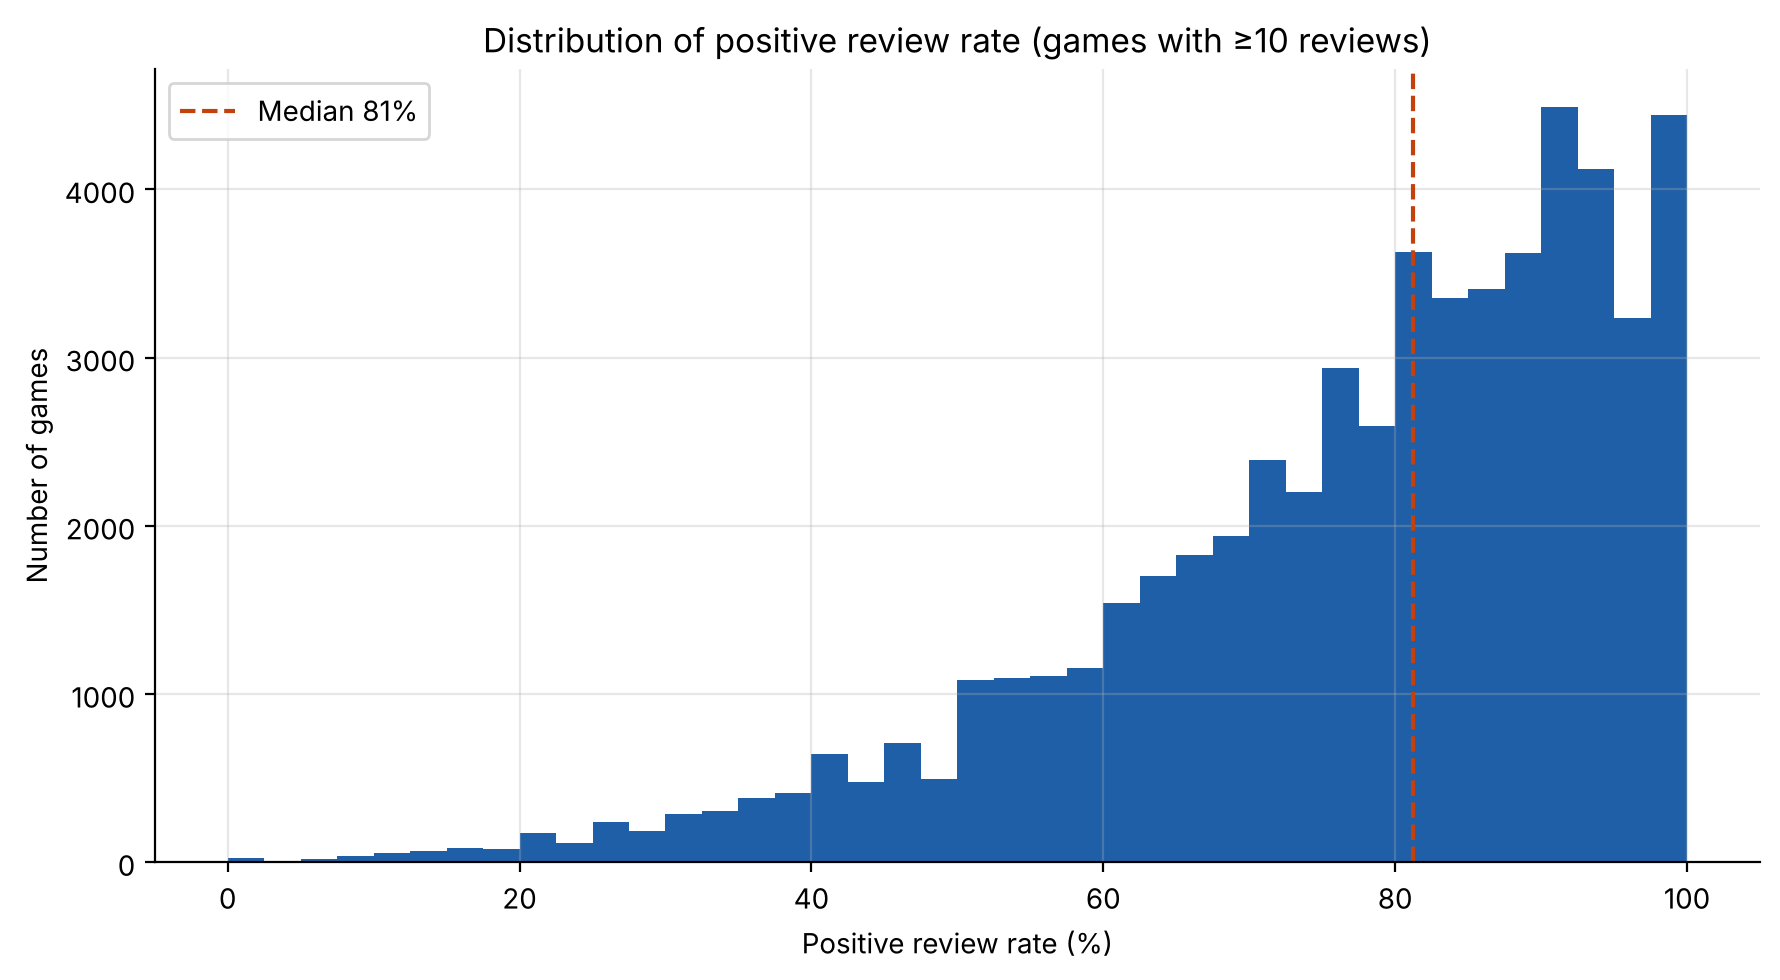

好评率中位数：81.2%
好评率 ≥ 80% 的游戏占比：53.5%
好评率 < 50%（差评多于好评）的游戏占比：8.4%


In [8]:
fig, ax = plt.subplots()
ax.hist(rated["positive_rate"] * 100, bins=40, color=BLUE)
median_rate = rated["positive_rate"].median()
ax.axvline(median_rate * 100, color="#C2410C", linestyle="--", label=f"Median {median_rate:.0%}")
ax.set_title("Distribution of positive review rate (games with ≥10 reviews)")
ax.set_xlabel("Positive review rate (%)")
ax.set_ylabel("Number of games")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "03_positive_rate_distribution.png", dpi=150)
plt.show()

print(f"好评率中位数：{median_rate:.1%}")
print(f"好评率 ≥ 80% 的游戏占比：{(rated['positive_rate'] >= 0.8).mean():.1%}")
print(f"好评率 < 50%（差评多于好评）的游戏占比：{(rated['positive_rate'] < 0.5).mean():.1%}")

## 6. 图 4：价格区间与好评率

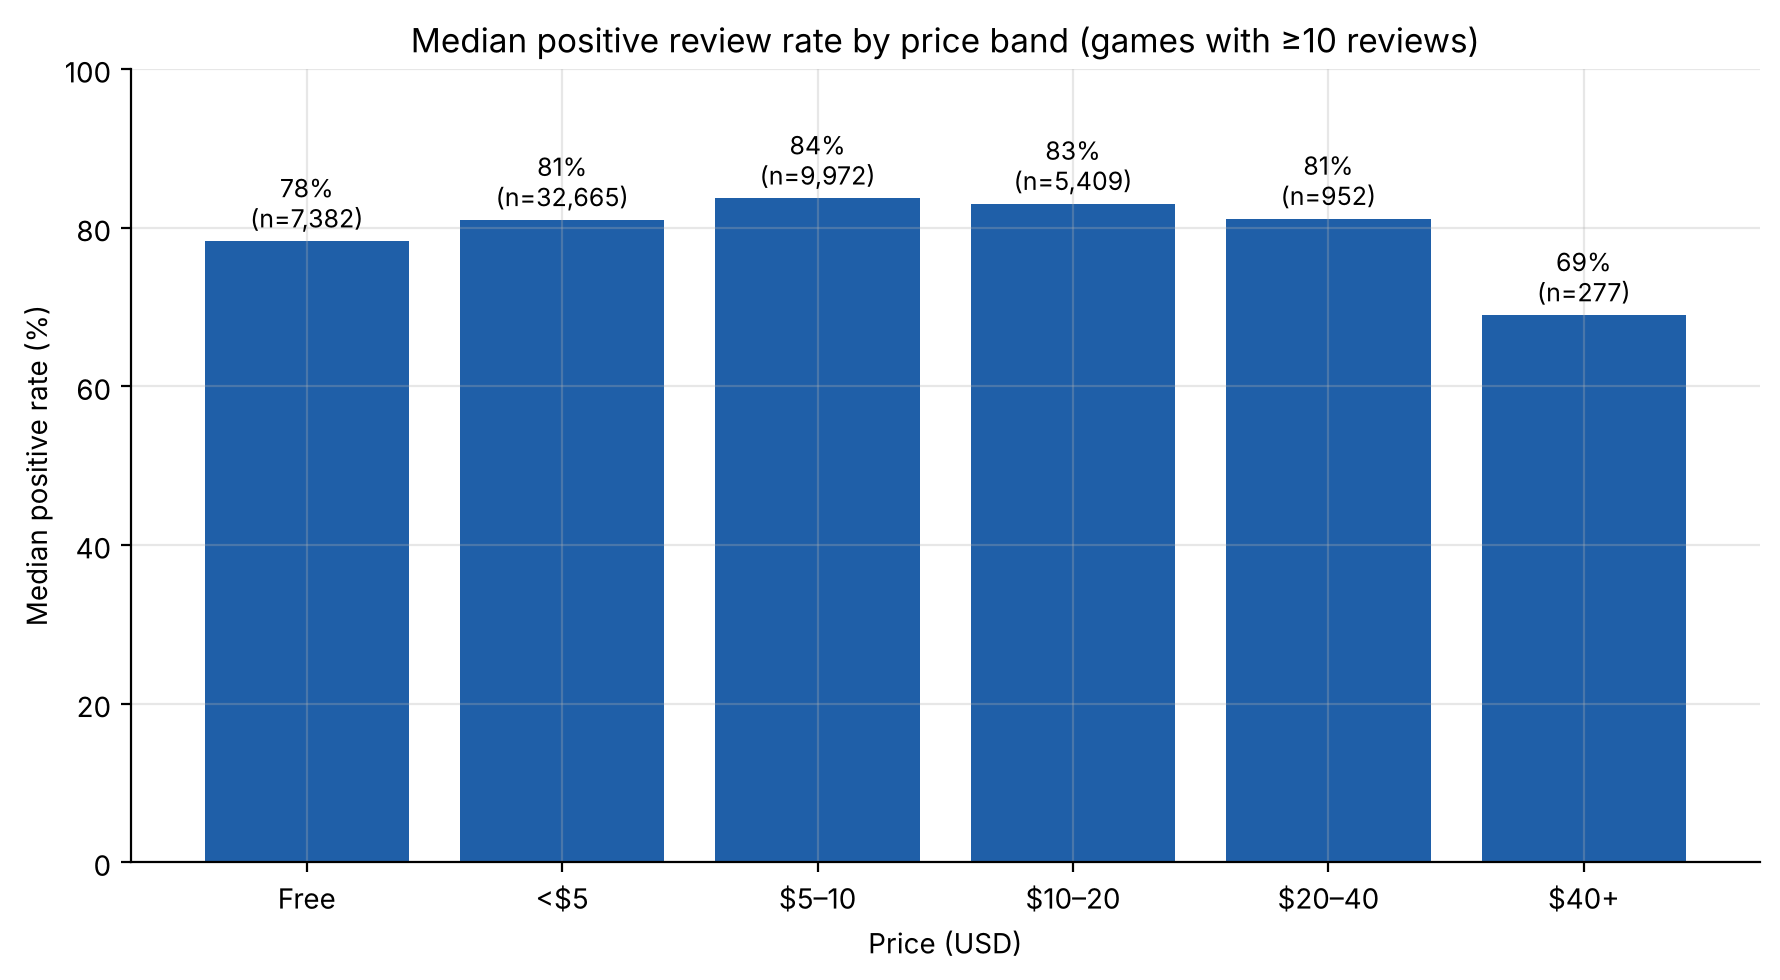

,median,count
price_band,,
Free,0.782638,7382
<$5,0.809524,32665
$5–10,0.836735,9972
$10–20,0.829932,5409
$20–40,0.810976,952
$40+,0.689516,277


In [9]:
bins = [-0.01, 0, 4.99, 9.99, 19.99, 39.99, np.inf]
labels = ["Free", "<$5", "$5–10", "$10–20", "$20–40", "$40+"]
rated["price_band"] = pd.cut(rated["price"], bins=bins, labels=labels)

by_price = rated.groupby("price_band", observed=True)["positive_rate"].agg(["median", "count"])

fig, ax = plt.subplots()
ax.bar(by_price.index.astype(str), by_price["median"] * 100, color=BLUE)
for i, (m, n) in enumerate(zip(by_price["median"], by_price["count"])):
    ax.text(i, m * 100 + 1, f"{m:.0%}\n(n={n:,})", ha="center", va="bottom", fontsize=9)
ax.set_ylim(0, 100)
ax.set_title("Median positive review rate by price band (games with ≥10 reviews)")
ax.set_xlabel("Price (USD)")
ax.set_ylabel("Median positive rate (%)")
fig.tight_layout()
fig.savefig(FIG_DIR / "04_price_vs_rating.png", dpi=150)
plt.show()

by_price

## 7. 第一阶段小结

运行上面的代码可以得到以下发现（数字以输出为准）：

1. **Steam 新游戏数量增长很快：** 2025 年发行约 2.5 万款，约为 2015 年的 10 倍；全部游戏中约 74% 发行于 2020–2025 年。
2. **独立游戏占绝对多数：** 约三分之二的游戏带有 Indie 标签。
3. **大多数游戏没有足够的评价：** 约 33% 的游戏没有任何评价，评价数 ≥ 10 的只有约 46%。在这些游戏中，好评率中位数约 81%。
4. **价格与好评率不是简单的"越贵越好"：** \$5–20 区间的好评率中位数最高（约 83–84%），免费游戏（约 78%）和 \$40 以上的游戏（约 69%）偏低。

**下一阶段计划：** 研究评价数量、游戏类型、发行年份、拥有人数等因素与好评率的关系，并检验价格的影响是否在控制其他因素后仍然存在。
